In [30]:
import pandas as pd
import matplotlib as plt

df = pd.read_csv('./penguins.csv')

df.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


<Axes: >

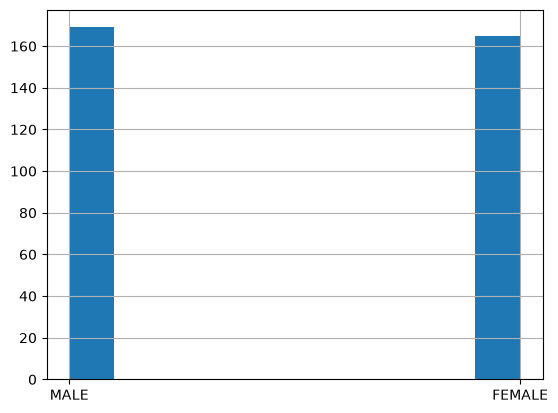

In [24]:
# Filtra la columna manteniendo solo lo que NO sea igual a '.'
df['sex'][df['sex'] != '.'].hist()

In [33]:
df = pd.read_csv('./penguins.csv')
mapa_sexo = {'FEMALE': 0, 'MALE': 1} # Ajusta los textos según cómo aparezcan exactamente
df['sex'] = df['sex'].map(mapa_sexo)
df

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,1.0
1,39.5,17.4,186.0,3800.0,0.0
2,40.3,18.0,195.0,3250.0,0.0
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,0.0
...,...,...,...,...,...
339,NaN,NaN,NaN,NaN,NaN
340,46.8,14.3,215.0,4850.0,0.0
341,50.4,15.7,222.0,5750.0,1.0
342,45.2,14.8,212.0,5200.0,0.0


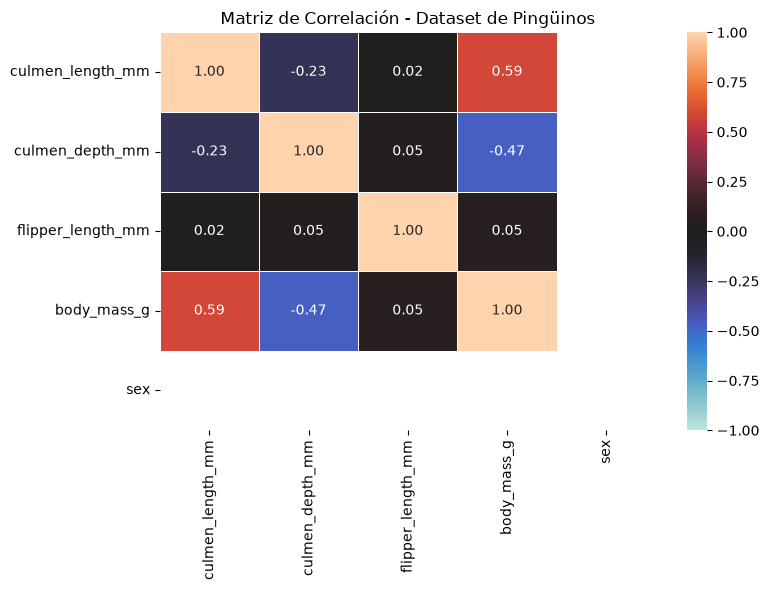

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# --- PASO 1: Limpieza y Conversión de Variables ---
# Reemplazamos el punto '.' por nulo y eliminamos las filas sin datos en 'sex'
df["sex"] = df["sex"].replace(".", np.nan)
df_limpio = df.dropna(subset=["sex"]).copy()

# Pasamos 'sex' a números (0 para FEMALE, 1 para MALE)
# Nota: Si tus etiquetas son distintas (ej. 'F' y 'M'), cámbialas en el diccionario
mapa_sexo = {"FEMALE": 0, "MALE": 1, "F": 0, "M": 1}
df_limpio["sex"] = df_limpio["sex"].map(mapa_sexo)


# --- PASO 2: Matriz de Correlación y Mapa de Calor ---
# Calculamos la correlación de todas tus columnas numéricas
corr = df_limpio.corr(numeric_only=True)

# Configuramos el tamaño de la figura para que se lea bien
plt.figure(figsize=(8, 6))

# Dibujamos el mapa de calor
sns.heatmap(
    corr,
    annot=True,  # Muestra los números dentro de cada celda
    cmap="YlGnBu",  # Muestra la paleta de colores azul/verde/amarillo
    vmin=-1,  # Límite mínimo de la escala de correlación
    vmax=1,  # Límite máximo de la escala de correlación
    center=0,  # El color neutro se centrará en el 0
    fmt=".2f",  # Muestra los números con solo 2 decimales
    linewidths=0.5,  # Añade una pequeña línea de separación entre celdas
)

plt.title("Matriz de Correlación - Dataset de Pingüinos")
plt.tight_layout()  # Ajusta los márgenes para que no se corten los textos
plt.show()